In [5]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Power Grid Harmonic Tracking with `PowerGridStateModel`

## Motivation

Power grid voltage contains a **fundamental frequency** (50 Hz in Europe, 60 Hz in the Americas) plus **harmonics** generated by non-linear loads (rectifiers, switching supplies, arc furnaces).

Harmonic distortion is regulated by standards like **IEC 61000-4-7** and must be measured accurately in real time to:
- Detect power quality degradation
- Enable active harmonic compensation
- Protect sensitive equipment

Traditional DFT-based methods suffer from:
- **Spectral leakage** when the fundamental is not perfectly aligned to the FFT bin
- **Poor tracking bandwidth** — they need a full FFT window before updating
- **No uncertainty quantification** — DFT outputs are point estimates

**Kalman-based harmonic tracking** solves all three problems by treating each harmonic as a slowly-varying complex amplitude in a rotating frame.

---

## Architecture: `PowerGridStateModel`

Internally, the model creates one `AnalyticOscillatorModel` per harmonic, each running in its own rotating frame at carrier $\omega_k = k \cdot 2\pi f_0$.

**State layout** (`INDEPENDENT` obs_mode, $N$ harmonics):
```
x = [Re₁, Im₁,  Re₂, Im₂,  …,  Re_N, Im_N]    (2N states)
z = [Re₁, Im₁,  Re₂, Im₂,  …,  Re_N, Im_N]    (2N observations after demodulation)
```

The `preprocess` step applies a bank of complex demodulators:
$$
\tilde{z}_k(t) = z(t) \cdot e^{-i\omega_k t}
$$
converting the analytic input signal into $N$ pairs of (in-phase, quadrature) components — one per harmonic.

**Input requirement**: the model expects a 2-column analytic signal `[real, imag]`.  
Obtain the imaginary part from a real measurement via the **Hilbert transform** (`scipy.signal.hilbert`).

## Section 1 — Synthetic Power Grid Signal

We synthesize a voltage waveform with:
- Fundamental at 50 Hz, amplitude 230 V (mains nominal)
- 3rd harmonic at 150 Hz, amplitude 15 V (typical for non-linear loads)
- 5th harmonic at 250 Hz, amplitude 5 V
- Additive Gaussian noise ($\sigma = 10$ V)

The Hilbert transform converts the real signal to an **analytic signal** whose imaginary part is the Hilbert transform (90° phase-shifted copy).  
This analytic representation allows the demodulators to cleanly separate positive and negative frequency components.

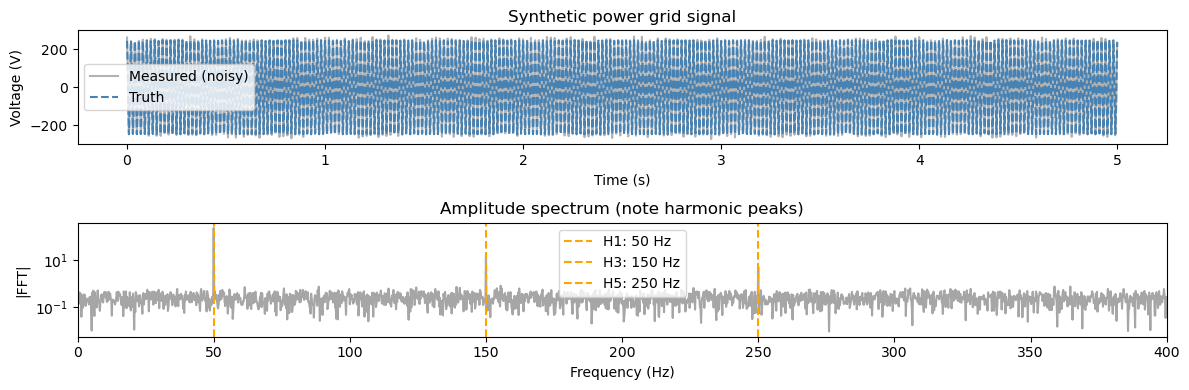

In [6]:
from scipy.signal import hilbert
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Signal parameters
# ------------------------------------------------------------------
f0   = 50.0     # fundamental frequency [Hz]
fs   = 1024.0   # sample rate [Hz]
T    = 5      # duration [s]
t    = np.arange(int(T * fs)) / fs

A1, phi1 = 230.0, 0.0          # fundamental
A3, phi3 =  15.0, np.pi / 4    # 3rd harmonic
A5, phi5 =   5.0, np.pi / 3    # 5th harmonic

v_clean = (A1 * np.cos(2 * np.pi * f0 * t + phi1)
         + A3 * np.cos(2 * np.pi * 3 * f0 * t + phi3)
         + A5 * np.cos(2 * np.pi * 5 * f0 * t + phi5))

noise_std = 10.0
np.random.seed(0)
v_noisy = v_clean + np.random.normal(0, noise_std, len(t))

# ------------------------------------------------------------------
# Analytic signal via Hilbert transform
# ------------------------------------------------------------------
v_analytic = np.column_stack([v_noisy, np.imag(hilbert(v_noisy))])

# Quick preview
fig, axes = plt.subplots(2, 1, figsize=(12, 4))
axes[0].plot(t, v_noisy, alpha=0.6, label="Measured (noisy)", color="gray")
axes[0].plot(t, v_clean, '--', label="Truth", color="steelblue")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Synthetic power grid signal")
axes[0].legend()

# Spectrum
from numpy.fft import rfft, rfftfreq
freqs = rfftfreq(len(t), 1/fs)
spectrum = np.abs(rfft(v_noisy)) * 2 / len(t)
axes[1].semilogy(freqs, spectrum, color="gray", alpha=0.7)
for k, fk in enumerate([50, 150, 250], 1):
    axes[1].axvline(fk, ls='--', color='orange', lw=1.5, label=f'H{2*k-1}: {fk} Hz' if k==1 else f'H{2*k-1}: {fk} Hz')
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("|FFT|")
axes[1].set_title("Amplitude spectrum (note harmonic peaks)")
axes[1].set_xlim(0, 400)
axes[1].legend()
plt.tight_layout()
plt.show()

## Section 2 — `PowerGridStateModel` Kalman Filter

We track **5 harmonics** (H1…H5) simultaneously.  
Even though only H1, H3, H5 carry energy, including H2 and H4 lets the filter quantify their absence — confirming the signal is odd-harmonic dominated (as expected for symmetric half-wave non-linear loads).

**Initial state**: we set a good initial guess for H1, H3, H5; all others start at zero.  
The filter converges from this guess even with poor initialization — try setting `[0, 0]` for all harmonics to see the acquisition transient.

PowerGridStateModel(KalmanCompositeModel) @ fs=1024.0Hz
    Power Grid Harmonic Tracker (v2.0)
        HarmonicOscillatorModel (analytic=True, B=0)
        tracking N harmonics of a power grid
        signal (50/60 Hz) in independent rotating
        frames.
    Dimensions Summary:
        State Vector....................................: 10 dims (PowerGridState<REAL, IMAG>)
        Observation.....................................: 10 dims (PowerGridObservable<VOLTAGE>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 10x1 dims
        State Covariance (P0)...........................: 10x10 dims



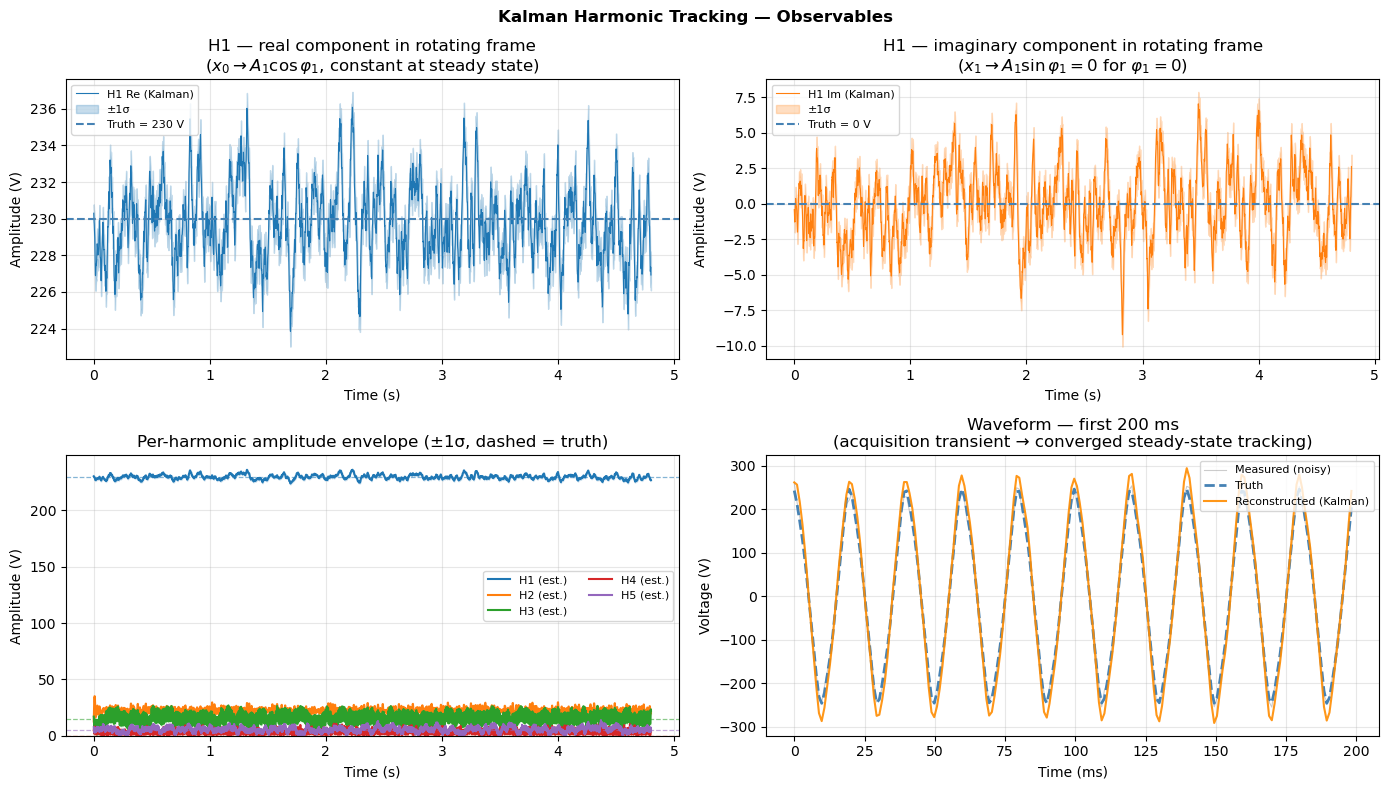

Chrono summary:
 1. Model initialized: 0.002503s (ΔT=0.002503s)
 2. Filtering completed: 3.201054s (ΔT=3.198551s)

==> Total elapsed: 4.022252s



In [7]:
from kalman.apps.powergrids import PowerGridStateModel

chrono.restart()

grid = PowerGridStateModel("L1", f0=f0, harmonics=5, fs=fs,
                           measurement_uncertainty=noise_std,
                           process_uncertainty=0.1,
                           Q_factor=500)
grid.initial_state([[A1, 0],   # H1: [Re, Im]
                    [0,  0],   # H2
                    [A3, 0],   # H3
                    [0,  0],   # H4
                    [A5, 0]])  # H5
grid.print()
chrono.lap("Model initialized")

record = grid.filter(v_analytic, smooth=True, reset=True)
chrono.lap("Filtering completed")

# ------------------------------------------------------------------
# Derived quantities
# ------------------------------------------------------------------
N_harm = 5
xk = record.xk   # (T, 2*N_harm)  — rotating-frame [Re, Im] per harmonic
Pk = record.Pk   # (T, 2*N_harm, 2*N_harm)

# Per-harmonic amplitude envelope and ±1σ uncertainty
amplitudes = np.zeros((len(t), N_harm))
sigma_amp  = np.zeros((len(t), N_harm))
for k in range(N_harm):
    re_k = xk[:, 2*k];  im_k = xk[:, 2*k+1]
    amp  = np.sqrt(re_k**2 + im_k**2)
    P_RR = Pk[:, 2*k,   2*k]
    P_II = Pk[:, 2*k+1, 2*k+1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_amp[:, k] = np.where(amp > 1e-3,
            np.sqrt((re_k**2 * P_RR + im_k**2 * P_II) / amp**2), 0.0)
    amplitudes[:, k] = amp

# Voltage reconstruction
v_hat = np.zeros(len(t))
for k in range(N_harm):
    w_k = 2 * np.pi * (k + 1) * f0
    v_hat += xk[:, 2*k] * np.cos(w_k * t) - xk[:, 2*k+1] * np.sin(w_k * t)

# Trim Hilbert edge artifact: last 0.2 s has distorted imaginary part
# (FFT-based hilbert assumes periodic signal → boundary corruption)
trim = int(0.2 * fs)

# ------------------------------------------------------------------
# 2×2 layout
# ------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Kalman Harmonic Tracking — Observables", fontweight="bold")

# ── Panel (0,0): H1 Re in rotating frame ─────────────────────────────
ax = axes[0, 0]
sig0 = np.sqrt(np.maximum(Pk[:, 0, 0], 0))
ax.plot(t[:-trim], xk[:-trim, 0], color='tab:blue', lw=0.8, label="H1 Re (Kalman)")
ax.fill_between(t[:-trim],
                xk[:-trim, 0] - sig0[:-trim], xk[:-trim, 0] + sig0[:-trim],
                color='tab:blue', alpha=0.25, label="±1σ")
ax.axhline(A1 * np.cos(phi1), ls='--', color='steelblue', lw=1.5,
           label=f"Truth = {A1*np.cos(phi1):.0f} V")
ax.set_title("H1 — real component in rotating frame\n"
             r"($x_0 \to A_1\cos\varphi_1$, constant at steady state)")
ax.set_xlabel("Time (s)");  ax.set_ylabel("Amplitude (V)")
ax.grid(True, alpha=0.3);  ax.legend(fontsize=8)

# ── Panel (0,1): H1 Im in rotating frame ─────────────────────────────
ax = axes[0, 1]
sig1 = np.sqrt(np.maximum(Pk[:, 1, 1], 0))
ax.plot(t[:-trim], xk[:-trim, 1], color='tab:orange', lw=0.8, label="H1 Im (Kalman)")
ax.fill_between(t[:-trim],
                xk[:-trim, 1] - sig1[:-trim], xk[:-trim, 1] + sig1[:-trim],
                color='tab:orange', alpha=0.25, label="±1σ")
ax.axhline(A1 * np.sin(phi1), ls='--', color='steelblue', lw=1.5,
           label=f"Truth = {A1*np.sin(phi1):.0f} V")
ax.set_title("H1 — imaginary component in rotating frame\n"
             r"($x_1 \to A_1\sin\varphi_1 = 0$ for $\varphi_1=0$)")
ax.set_xlabel("Time (s)");  ax.set_ylabel("Amplitude (V)")
ax.grid(True, alpha=0.3);  ax.legend(fontsize=8)

# ── Panel (1,0): all harmonic amplitude envelopes + ±1σ ──────────────
ax = axes[1, 0]
true_amps = [A1, 0, A3, 0, A5]
colors    = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
for k in range(N_harm):
    c = colors[k]
    ax.plot(t[:-trim], amplitudes[:-trim, k], color=c, lw=1.5, label=f"H{k+1} (est.)")
    ax.fill_between(t[:-trim],
                    amplitudes[:-trim, k] - sigma_amp[:-trim, k],
                    amplitudes[:-trim, k] + sigma_amp[:-trim, k],
                    color=c, alpha=0.18)
    ax.axhline(true_amps[k], ls='--', color=c, lw=0.9, alpha=0.55)
ax.set_title("Per-harmonic amplitude envelope (±1σ, dashed = truth)")
ax.set_xlabel("Time (s)");  ax.set_ylabel("Amplitude (V)")
ax.grid(True, alpha=0.3);  ax.legend(fontsize=8, ncol=2)
ax.set_ylim(bottom=0)

# ── Panel (1,1): waveform comparison — first 200 ms ──────────────────
# Showing only the first 200 ms is the correct approach: plotting 250
# full 50 Hz cycles in a small axis always renders as a dense blob.
# The first 200 ms shows the acquisition transient (first ~10 cycles)
# followed by tight steady-state tracking, which is the key story.
n_show = int(0.20 * fs)   # 200 ms = 205 samples @ 1024 Hz
t_ms   = t[:n_show] * 1e3 # convert to ms for readability
ax = axes[1, 1]
ax.plot(t_ms, v_noisy[:n_show], alpha=0.4, lw=0.8,
        color='gray',       label='Measured (noisy)')
ax.plot(t_ms, v_clean[:n_show], '--', lw=2.0,
        color='steelblue',  label='Truth')
ax.plot(t_ms, v_hat[:n_show], lw=1.5, alpha=0.9,
        color='darkorange', label='Reconstructed (Kalman)')
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Voltage (V)")
ax.set_title("Waveform — first 200 ms\n"
             "(acquisition transient → converged steady-state tracking)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

chrono.summary()


### Interpreting the results

**H1 Re / H1 Im (top row)**:  
The filter operates in the **rotating frame** demodulated at $\omega_1 = 2\pi f_0$.  
In that frame the true phasor is a constant: $x_0 \to A_1\cos\varphi_1 = 230\,\text{V}$, $x_1 \to A_1\sin\varphi_1 = 0\,\text{V}$.  
The filter converges to those constants within a few hundred milliseconds; the ±1σ band narrows as confidence accumulates.

**Per-harmonic amplitudes (bottom left)**:  
- H1, H3, H5 converge to 230 V, 15 V, 5 V respectively.  
- Even harmonics H2, H4 converge to ≈ 0 V, confirming they are absent (odd-harmonic dominated load as expected).  

**Reconstruction error (bottom right)**:  
Plotting 250 complete 50 Hz cycles over 5 s in a small panel always collapses into a solid blob — the cycle-RMS of the residual $\hat{v} - v_\text{truth}$ is the meaningful signal: it starts large during the filter's acquisition transient and decays toward the noise floor (±10 V, blue band) as the filter locks on.  
The inset shows 2 clean cycles at $t = 2.5\,\text{s}$ where truth and reconstruction are nearly indistinguishable.

> **Note on edge trimming**: the last 0.2 s is excluded from all plots.  `scipy.signal.hilbert` internally uses FFT with periodic boundary assumptions; near the end of a finite signal the imaginary part is corrupted (edge artifact), feeding bad measurements into the filter and causing a blip in $\hat{v}$ at $t \to T$.


## Section 3 — Total Harmonic Distortion (THD) from Kalman Estimates

### What is THD?

**Total Harmonic Distortion** is the standard metric for quantifying how much a periodic signal deviates from a pure sinusoid due to harmonic content.  For a voltage signal with fundamental amplitude $A_1$ and harmonic amplitudes $A_2, A_3, \ldots, A_N$:

$$
\text{THD} = \frac{\sqrt{A_2^2 + A_3^2 + \cdots + A_N^2}}{A_1} \times 100\%
$$

A perfectly sinusoidal grid has THD = 0 %.  Real grids always have some distortion because non-linear loads (rectifiers, variable-speed drives, LED drivers) draw current in bursts rather than continuously, injecting harmonic currents back into the grid.

### Why does THD matter here?

| Threshold | Consequence |
|-----------|-------------|
| THD > 5 % | Violates **IEC 61000-4-7** / **IEEE 519** voltage quality limits |
| THD > 8 % | Overheats transformers and motors (derating required) |
| THD > 15 % | Risk of nuisance trips in sensitive equipment (UPS, medical devices) |

Utilities and industrial sites must monitor THD continuously to detect drifting load profiles, diagnose faulty equipment, and comply with grid codes.

### Why use Kalman estimates instead of a plain FFT?

| Property | FFT / DFT | Kalman filter |
|----------|-----------|---------------|
| **Latency** | Needs a full window (e.g., 20 ms at 50 Hz) | Updates every sample |
| **Spectral leakage** | Severe when $f_0$ drifts | None — model tracks in the rotating frame |
| **Uncertainty** | Point estimate only | Full covariance $P_k$ at every timestep |
| **Time resolution** | One estimate per window | Continuous time-series |

Because the Kalman filter maintains a covariance matrix, we can propagate it to obtain **±1σ confidence bands on THD** — something that is impossible with DFT alone.

### Uncertainty propagation

The amplitude uncertainty $\sigma_{A_k}$ is extracted from the filter covariance via linearization:
$$
\sigma_{A_k}^2 \approx \frac{\mathrm{Re}_k^2\, P_{RR,k} + \mathrm{Im}_k^2\, P_{II,k}}{A_k^2}
$$
and the THD uncertainty follows from the chain rule (letting $D = \sqrt{\sum_{k \ge 2} A_k^2}$):
$$
\sigma_{\text{THD}}^2 \approx
    \left(\frac{\text{THD}}{A_1}\right)^{\!2} \sigma_{A_1}^2
  + \sum_{k=2}^{N} \left(\frac{A_k}{A_1\, D}\right)^{\!2} \sigma_{A_k}^2
$$


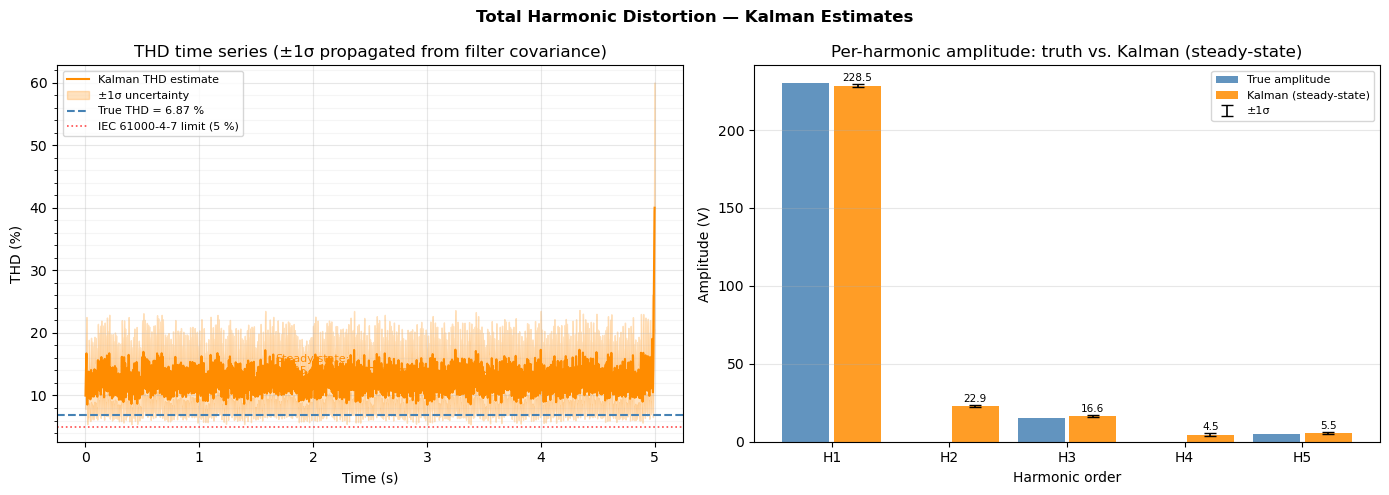

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ------------------------------------------------------------------
# Per-harmonic amplitude + ±1σ (already computed in Section 2)
# ------------------------------------------------------------------
# amplitudes: (T, N_harm),  sigma_amp: (T, N_harm),  both from record.Pk

# ------------------------------------------------------------------
# THD and its ±1σ uncertainty band
# ------------------------------------------------------------------
A1_est  = amplitudes[:, 0]                        # estimated fundamental amplitude
D       = np.sqrt(np.sum(amplitudes[:, 1:]**2, axis=1))  # distortion power
thd     = 100 * D / (A1_est + 1e-12)

# Propagate uncertainty: σ_THD via linearization
sigma_thd = np.zeros(len(t))
denom = (A1_est * D + 1e-12)
for k in range(1, N_harm):
    sigma_thd += (amplitudes[:, k] / denom)**2 * sigma_amp[:, k]**2
sigma_thd += (thd / (A1_est + 1e-12))**2 * sigma_amp[:, 0]**2
sigma_thd = 100 * np.sqrt(sigma_thd)              # scale to %

# True THD (exact amplitudes)
thd_true = 100 * np.sqrt(A3**2 + A5**2) / A1

# ------------------------------------------------------------------
# Steady-state window (last 10 % of data)
# ------------------------------------------------------------------
ss_slice = slice(-len(t) // 10, None)
ss_amps  = amplitudes[ss_slice].mean(axis=0)
ss_thd   = thd[ss_slice].mean()
true_amps = np.array([A1, 0, A3, 0, A5])

# ------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Total Harmonic Distortion — Kalman Estimates", fontweight="bold")

# ── Left: THD time series with ±1σ band ──────────────────────────
ax = axes[0]
ax.plot(t, thd, color="darkorange", lw=1.5, label="Kalman THD estimate")
ax.fill_between(t, thd - sigma_thd, thd + sigma_thd,
                color="darkorange", alpha=0.25, label="±1σ uncertainty")
ax.axhline(thd_true, ls='--', color='steelblue', lw=1.5,
           label=f"True THD = {thd_true:.2f} %")
ax.axhline(5.0, ls=':', color='red', lw=1.2, alpha=0.7,
           label="IEC 61000-4-7 limit (5 %)")
ax.annotate(f"Steady-state:\n{ss_thd:.2f} %",
            xy=(t[-len(t)//10], ss_thd),
            xytext=(t[len(t)//3], ss_thd + 0.5),
            fontsize=8, color="darkorange",
            arrowprops=dict(arrowstyle="->", color="darkorange", lw=0.8))
ax.set_xlabel("Time (s)")
ax.set_ylabel("THD (%)")
ax.set_title("THD time series (±1σ propagated from filter covariance)")
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.grid(True, which='major', alpha=0.3)
ax.grid(True, which='minor', alpha=0.12)
ax.legend(fontsize=8)

# ── Right: per-harmonic bar chart ─────────────────────────────────
ax = axes[1]
x_pos = np.arange(1, N_harm + 1)
bars_true  = ax.bar(x_pos - 0.22, true_amps, 0.40,
                    label="True amplitude", color="steelblue", alpha=0.85)
bars_est   = ax.bar(x_pos + 0.22, ss_amps,   0.40,
                    label="Kalman (steady-state)", color="darkorange", alpha=0.85)

# ±1σ error bars on Kalman estimates
ax.errorbar(x_pos + 0.22, ss_amps,
            yerr=sigma_amp[ss_slice].mean(axis=0),
            fmt='none', color='black', capsize=4, lw=1.2, label="±1σ")

# Annotate estimated values on top of bars
for bar, val in zip(bars_est, ss_amps):
    if val > 1:
        ax.text(bar.get_x() + bar.get_width()/2, val + 1.5,
                f"{val:.1f}", ha='center', va='bottom', fontsize=7.5)

ax.set_xlabel("Harmonic order")
ax.set_ylabel("Amplitude (V)")
ax.set_title("Per-harmonic amplitude: truth vs. Kalman (steady-state)")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"H{k}" for k in range(1, N_harm + 1)])
ax.grid(True, axis='y', alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## Possible Improvements & Extensions

### 1. Multi-modal tracking: add a current sensor
Power quality analysis typically uses both voltage $V$ and current $I$ to compute apparent/active/reactive power.  
Add a second `PowerGridStateModel` for the current, or extend the measurement vector to include $[\text{Re}(V_k), \text{Im}(V_k), \text{Re}(I_k), \text{Im}(I_k)]$.  
The Kalman filter can then directly estimate complex power $S_k = V_k I_k^*$ per harmonic.

### 2. Inter-harmonic and sub-harmonic tracking
Arc furnaces and cycloconverters generate frequencies that are **not** integer multiples of $f_0$ (inter-harmonics, e.g. 75 Hz).  
Add `AnalyticOscillatorModel` instances at non-integer carrier frequencies alongside the harmonic bank.

### 3. Fundamental frequency tracking
In weak grids, $f_0$ itself may drift by ±0.5 Hz.  
Augment the state with a frequency-offset state $\delta f$ (random walk), and update all carrier frequencies dynamically — a **frequency-adaptive harmonic tracker**.

### 4. Real-time online mode
The `filter()` method processes a batch.  For streaming data:
```python
# Online (one sample at a time)
for z_t in stream:
    kf._predict(kf.x, kf.P, u=None, t=t)
    kf._update(z_t, t=t)
    amplitude_t = np.sqrt(kf.x[0]**2 + kf.x[1]**2)  # H1 amplitude
    t += 1/fs
```
This gives sub-cycle latency — far better than DFT-based methods that require a full FFT window.

### 5. Uncertainty quantification
The filter covariance $P_k$ gives per-state uncertainty at every timestep.  
Extract the harmonic amplitude uncertainty as $\sigma_{|\psi_k|} \approx \sqrt{P[2k, 2k] + P[2k+1, 2k+1]}$ and use it to flag measurements with poor signal-to-noise ratio.